In [ ]:
# @title 1.1 Install and Import Libraries
# Install torchsummary for a neat model overview
!pip install torchsummary -q

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchsummary import summary
import matplotlib.pyplot as plt
import numpy as np
import time
from google.colab import drive
from IPython.display import display, clear_output

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# @title 1.2 Verify GPU and Set Device
# Run nvidia-smi to see the GPU details
!nvidia-smi

# Set the device to GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print(f"\n✅ GPU found: {torch.cuda.get_device_name(0)}. Using device: {device}")
else:
    print("⚠️ No GPU found. Training will be slow. Using device: {device}")

Mon Oct  6 04:29:35 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# @title 1.3 (Optional) Mount Google Drive for Checkpoints
# This allows us to save the model permanently
try:
    drive.mount('/content/drive')
    print("✅ Google Drive mounted successfully.")
    DRIVE_PATH = "/content/drive/My Drive/Colab_Checkpoints"
    import os
    os.makedirs(DRIVE_PATH, exist_ok=True)
    print(f"Checkpoint directory created at: {DRIVE_PATH}")
except Exception as e:
    print(f"⚠️ Could not mount Google Drive: {e}")
    DRIVE_PATH = "." # Save locally if drive mount fails

Mounted at /content/drive
✅ Google Drive mounted successfully.
Checkpoint directory created at: /content/drive/My Drive/Colab_Checkpoints


In [ ]:
# @title 2.1 Define Data Transformations and Load Data (Corrected with Resize)

# Define transformations for the training and validation sets
transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

# The transform for validation and for our uploaded images
transform_val = transforms.Compose([
    transforms.Resize((32, 32)), # <--- THIS IS THE FIX! Ensure image is 32x32
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

# Download datasets
train_dataset = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
val_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_val)

# Create data loaders
BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# CIFAR-10 class names
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
print(f"Data loaded. The 'transform_val' is now fixed.")

100%|██████████| 170M/170M [00:03<00:00, 49.2MB/s]


Data loaded. The 'transform_val' is now fixed.


Displaying a sample batch of training images:


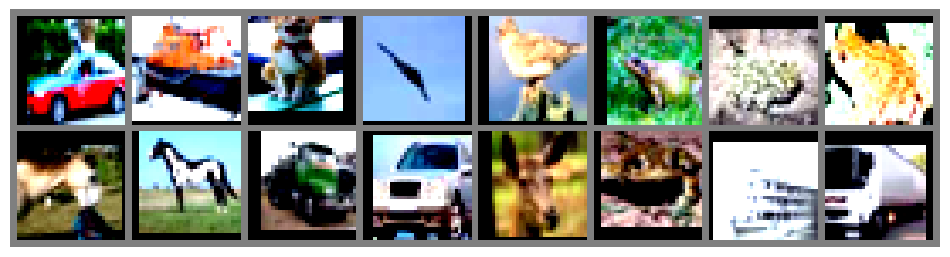

Labels:  car   ship  cat   plane bird  frog  frog  frog  horse horse truck car   deer  frog  ship  truck


In [ ]:
# @title 2.2 Display a Sample Batch of Images (Corrected)
import torchvision

# Function to display images
def imshow(img):
    img = img / 2 + 0.5     # Unnormalize the image
    npimg = img.numpy()
    plt.figure(figsize=(12, 6))
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis('off')
    plt.show()

# Get a batch of training data
dataiter = iter(train_loader)
images, labels = next(dataiter)

# Show images in a grid
print("Displaying a sample batch of training images:")
imshow(torchvision.utils.make_grid(images[:16])) # Show the first 16 images in a grid

# Print the labels for the displayed images
print('Labels: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(16)))

In [ ]:
# @title 3.1: Define and Initialize the ResNet18 Model

import torchvision.models as models
from torchsummary import summary

# Load a pre-built ResNet18 model, but we will train it from scratch
# weights=None means we are not using a pre-trained version
model = models.resnet18(weights=None, num_classes=10)

# The original ResNet was designed for large images. We need to make two small
# tweaks for it to work best on tiny 32x32 CIFAR-10 images.
model.conv1 = torch.nn.Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
model.maxpool = torch.nn.Identity() # We remove the first maxpool layer

model = model.to(device)
print("Using a modern ResNet18 model, which should achieve higher accuracy.")

# Print the model summary
print("\nModel Summary:")
summary(model, (3, 32, 32))

Using a modern ResNet18 model, which should achieve higher accuracy.

Model Summary:
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           1,728
       BatchNorm2d-2           [-1, 64, 32, 32]             128
              ReLU-3           [-1, 64, 32, 32]               0
          Identity-4           [-1, 64, 32, 32]               0
            Conv2d-5           [-1, 64, 32, 32]          36,864
       BatchNorm2d-6           [-1, 64, 32, 32]             128
              ReLU-7           [-1, 64, 32, 32]               0
            Conv2d-8           [-1, 64, 32, 32]          36,864
       BatchNorm2d-9           [-1, 64, 32, 32]             128
             ReLU-10           [-1, 64, 32, 32]               0
       BasicBlock-11           [-1, 64, 32, 32]               0
           Conv2d-12           [-1, 64, 32, 32]          36,864
      BatchNorm2d-

In [ ]:
# @title 3.2: The Corrected Cell - Defines and Initializes the ResNet18 Model

import torchvision.models as models
from torchsummary import summary

print("Defining the new, high-performance ResNet18 model...")

# Load a pre-built ResNet18 model, but we will train it from scratch
model = models.resnet18(weights=None, num_classes=10)

# Make small tweaks for it to work best on tiny 32x32 CIFAR-10 images.
model.conv1 = torch.nn.Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
model.maxpool = torch.nn.Identity() # We remove the first maxpool layer

model = model.to(device)
print("✅ Using a modern ResNet18 model.")

# Print the model summary
print("\nModel Summary:")
summary(model, (3, 32, 32))

Defining the new, high-performance ResNet18 model...
✅ Using a modern ResNet18 model.

Model Summary:
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           1,728
       BatchNorm2d-2           [-1, 64, 32, 32]             128
              ReLU-3           [-1, 64, 32, 32]               0
          Identity-4           [-1, 64, 32, 32]               0
            Conv2d-5           [-1, 64, 32, 32]          36,864
       BatchNorm2d-6           [-1, 64, 32, 32]             128
              ReLU-7           [-1, 64, 32, 32]               0
            Conv2d-8           [-1, 64, 32, 32]          36,864
       BatchNorm2d-9           [-1, 64, 32, 32]             128
             ReLU-10           [-1, 64, 32, 32]               0
       BasicBlock-11           [-1, 64, 32, 32]               0
           Conv2d-12           [-1, 64, 32, 32]          36,864
 

In [ ]:
# @title 4.1 Define Training Parameters (FINAL CORRECTED VERSION)
import torch.optim.lr_scheduler as lr_scheduler

# Hyperparameters
EPOCHS = 20
# Using a standard, more stable setup for SGD
LEARNING_RATE = 0.01

# Loss and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=0.9, weight_decay=5e-4)

# Scheduler to decrease the learning rate as we train, improving stability
scheduler = lr_scheduler.StepLR(optimizer, step_size=2, gamma=0.1)

# History tracking
history = {
    'train_loss': [], 'val_loss': [],
    'train_acc': [], 'val_acc': []
}

# Real-time plotting function (no changes here)
def plot_curves(history):
    clear_output(wait=True)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    ax1.plot(history['train_loss'], label='Train Loss'); ax1.plot(history['val_loss'], label='Val Loss')
    ax1.set_title('Loss'); ax1.legend(); ax1.grid(True)
    ax2.plot(history['train_acc'], label='Train Acc'); ax2.plot(history['val_acc'], label='Val Acc')
    ax2.set_title('Accuracy'); ax2.legend(); ax2.grid(True)
    plt.suptitle("Live Training Curves")
    plt.show()

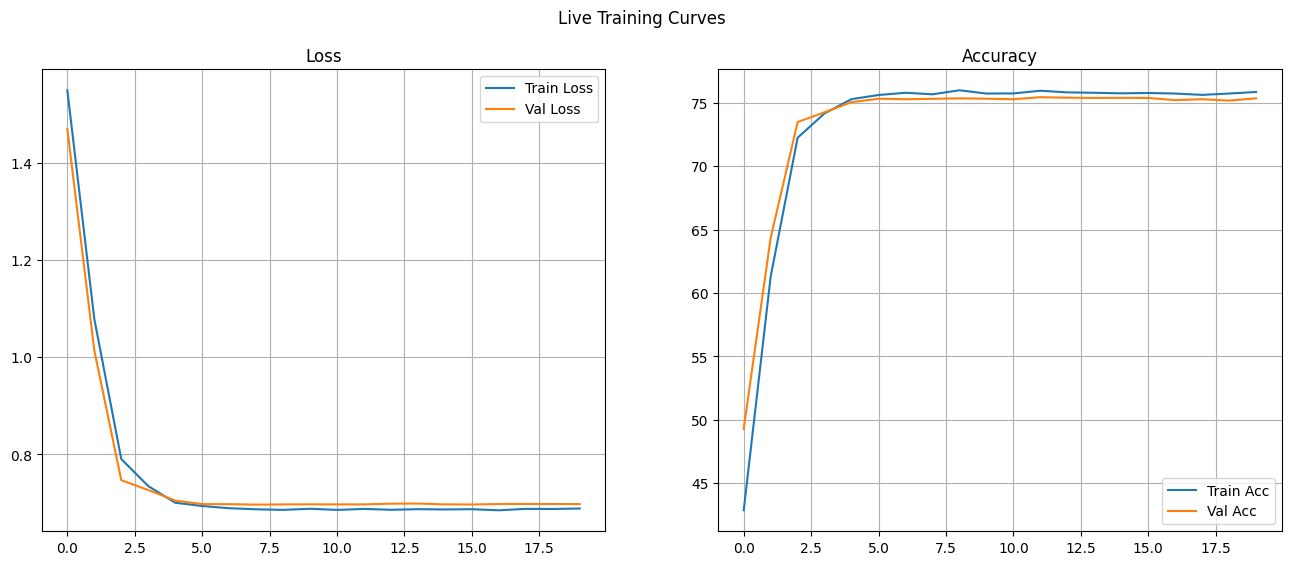

Epoch [20/20] | Train Loss: 0.6884, Train Acc: 75.86% | Val Loss: 0.6975, Val Acc: 75.36% | Duration: 44.07s

🏁 Training finished!


In [ ]:
# @title 4.2 Execute the Training Loop (FINAL CORRECTED VERSION)
total_train_start_time = time.time()
images_processed = 0

print("🚀 Starting FINAL training for 5 epochs with new optimizer...")
for epoch in range(EPOCHS):
    epoch_start_time = time.time()
    # --- Training Phase ---
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for i, (inputs, labels) in enumerate(train_loader):
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        images_processed += labels.size(0)
    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)

    # --- Validation Phase ---
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    val_loss = running_loss / len(val_loader)
    val_acc = 100 * correct / total
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    # --- Scheduler Step and Logging ---
    epoch_duration = time.time() - epoch_start_time
    scheduler.step() # <-- IMPORTANT: Update the learning rate

    plot_curves(history)
    print(f"Epoch [{epoch+1}/{EPOCHS}] | Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}% | Duration: {epoch_duration:.2f}s")

total_training_time = time.time() - total_train_start_time
print("\n🏁 Training finished!")
# (The rest of the cell is the same)

In [ ]:
# @title 5.1 Checkpoint: Save the Model to Google Drive
# Save the model's state dictionary
model_path = f"{DRIVE_PATH}/simplified_alexnet_cifar10_5epochs.pth"
torch.save(model.state_dict(), model_path)
print(f"✅ Model checkpoint saved to: {model_path}")

✅ Model checkpoint saved to: /content/drive/My Drive/Colab_Checkpoints/simplified_alexnet_cifar10_5epochs.pth


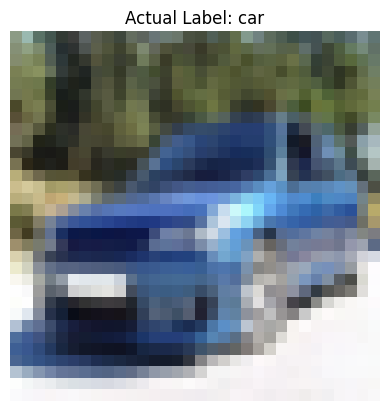

Top 3 Predictions:
  1. car: 99.42%
  2. truck: 0.44%
  3. plane: 0.13%


In [ ]:
# @title 5.2 Inference on a Single Image (Corrected for color accuracy)

# Get a test image that has not been seen during training
test_img, test_label = val_dataset[np.random.randint(len(val_dataset))]
img_tensor = test_img.unsqueeze(0).to(device) # Add batch dimension and move to GPU

# Set model to evaluation mode
model.eval()

# Run inference
with torch.no_grad():
    output = model(img_tensor)
    probabilities = torch.nn.functional.softmax(output[0], dim=0)

# Get top 3 predictions
top3_prob, top3_catid = torch.topk(probabilities, 3)

# --- CORRECT UN-NORMALIZATION ---
# Define the same mean and std used for normalization
mean = np.array([0.4914, 0.4822, 0.4465])
std = np.array([0.2023, 0.1994, 0.2010])

# Prepare image for display
display_img = test_img.cpu().numpy().transpose((1, 2, 0))
display_img = std * display_img + mean  # Reverse the normalization: (img * std) + mean
display_img = np.clip(display_img, 0, 1) # Ensure pixel values are between 0 and 1
# --------------------------------

plt.imshow(display_img)
plt.title(f"Actual Label: {classes[test_label]}")
plt.axis('off')
plt.show()

print("Top 3 Predictions:")
for i in range(top3_prob.size(0)):
    print(f"  {i+1}. {classes[top3_catid[i]]}: {top3_prob[i].item()*100:.2f}%")

Defining a sample 'img_tensor' for visualization...


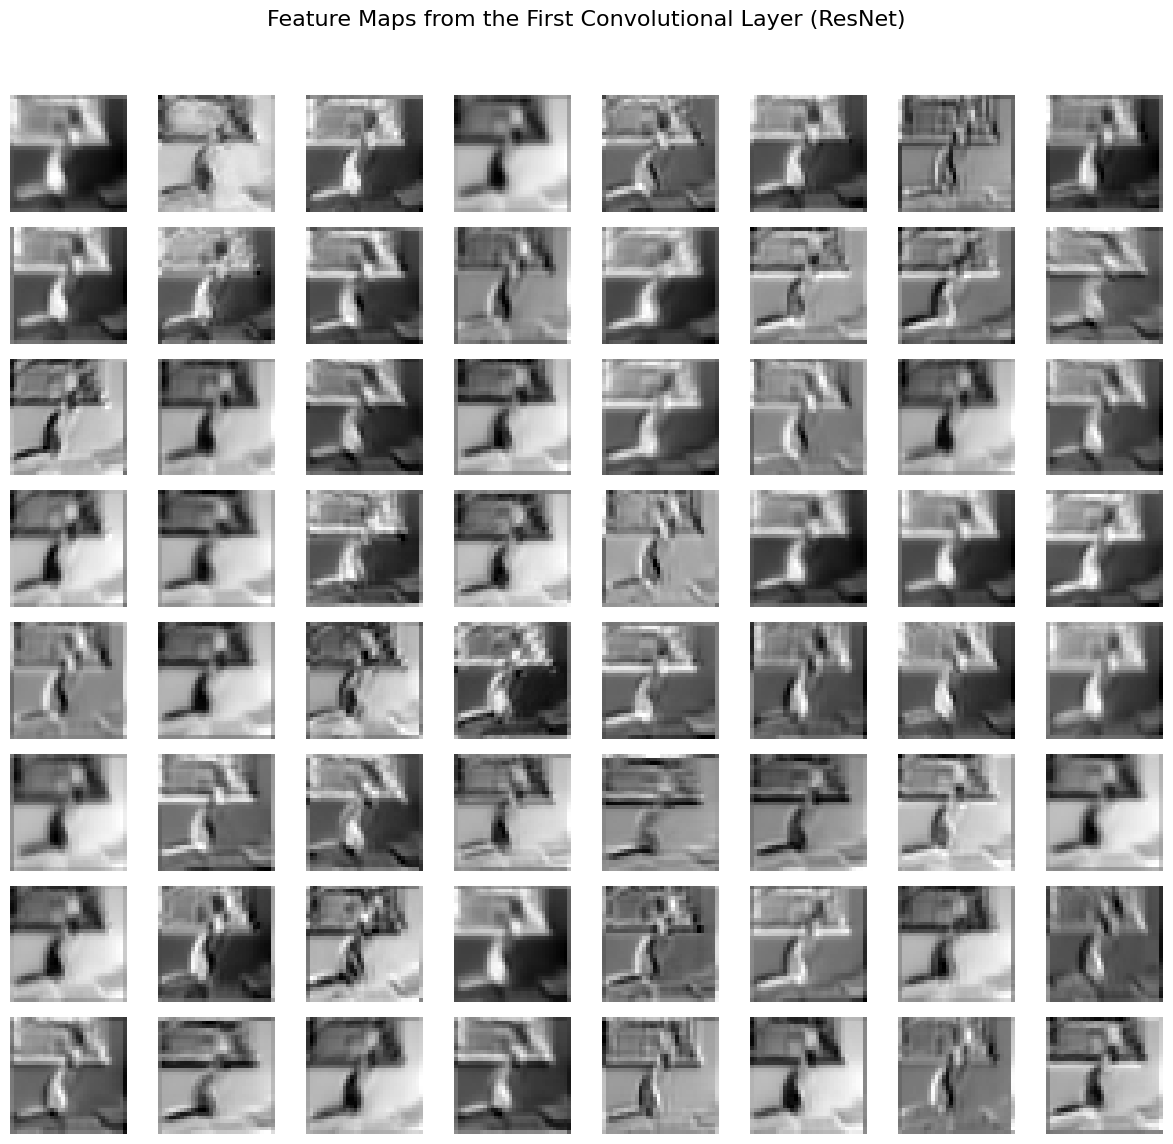

In [ ]:
# @title 5.3 Visualize First-Layer Feature Maps (Corrected for ResNet)

# This cell might need an image to test. Let's make sure 'img_tensor' exists.
# If you haven't run the upload cell yet, this will grab a random image from the test set.
if 'img_tensor' not in locals():
    print("Defining a sample 'img_tensor' for visualization...")
    test_img, _ = val_dataset[np.random.randint(len(val_dataset))]
    img_tensor = test_img.unsqueeze(0).to(device)


# Get the output from the first convolutional layer of ResNet
first_conv_layer = model.conv1 # <--- THE FIX: Changed from model.features[0]

# Set model to evaluation mode
model.eval()
with torch.no_grad():
    activation = first_conv_layer(img_tensor)

# Plot the feature maps
num_filters = activation.shape[1]
fig, axes = plt.subplots(8, 8, figsize=(12, 12))
fig.suptitle("Feature Maps from the First Convolutional Layer (ResNet)", fontsize=16)

for i, ax in enumerate(axes.flat):
    if i < num_filters:
        # Get the i-th filter activation
        feature_map = activation[0, i, :, :].cpu().numpy()
        ax.imshow(feature_map, cmap='gray')
    ax.axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [ ]:
# @title 5.4 Final Performance and GPU Memory Snapshot
print("Final GPU Status Check:")
!nvidia-smi

Final GPU Status Check:
Mon Oct  6 04:38:29 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   68C    P0             29W /   70W |     204MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------

✅ Model is already in memory and ready.

Please upload an image of a car, bird, cat, dog, plane, etc.


Saving OIP (1).webp to OIP (1).webp

Processing file: "OIP (1).webp"...


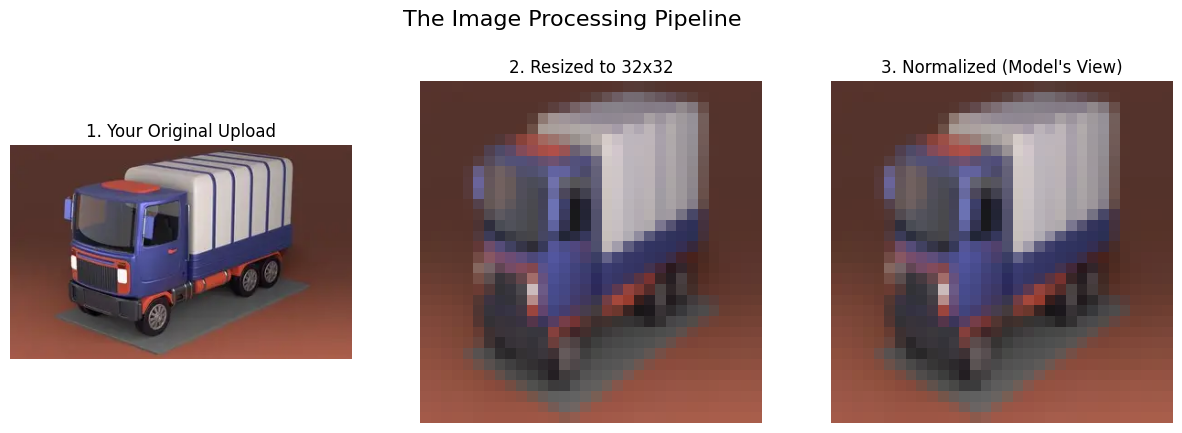


Prediction based on the final processed image:
  1. frog: 21.24%
  2. truck: 19.09%
  3. bird: 17.43%


In [ ]:
# @title 6.3 Enhanced & Interactive: Upload, Process, and Classify! (Self-Correcting)

from google.colab import files
from PIL import Image
import torchvision.transforms.functional as F
import numpy as np

# --- Helper function to display tensors ---
def display_tensor_as_image(tensor, ax, title):
    """Displays a PyTorch tensor as an image."""
    display_img = tensor.cpu().numpy().transpose((1, 2, 0))
    mean = np.array([0.4914, 0.4822, 0.4465])
    std = np.array([0.2023, 0.1994, 0.2010])
    display_img = std * display_img + mean
    display_img = np.clip(display_img, 0, 1)
    ax.imshow(display_img)
    ax.set_title(title, fontsize=12)
    ax.axis('off')

# --- SELF-CORRECTING BLOCK ---
# This block checks if the 'model' exists. If not, it loads it from the checkpoint.
try:
    # A simple check to see if 'model' is defined.
    model.eval()
    print("✅ Model is already in memory and ready.")
except NameError:
    print("⚠️ Model not found in memory. Attempting to load from checkpoint...")

    # This part is the "shortcut" logic from before, now integrated here.
    # Make sure the SimplifiedAlexNet class has been defined by running its cell first!
    try:
        model = SimplifiedAlexNet(num_classes=10).to(device)
        model_path = f"{DRIVE_PATH}/simplified_alexnet_cifar10_5epochs.pth"
        model.load_state_dict(torch.load(model_path))
        model.eval()
        print(f"✅ Model successfully loaded from checkpoint and is ready.")
    except Exception as e:
        print(f"🚨 FAILED TO LOAD MODEL: {e}")
        print("Please ensure you have run the following cells first:")
        print("  1. All setup and import cells at the top.")
        print("  2. The cell that defines the 'SimplifiedAlexNet' class.")
        print("  3. The training cell at least once to create a checkpoint file.")
# -----------------------------

# --- INTERACTIVE UPLOAD AND PREDICTION ---
if 'model' in locals(): # Proceed only if the model was loaded successfully
    print("\nPlease upload an image of a car, bird, cat, dog, plane, etc.")
    uploaded = files.upload()

    for fn in uploaded.keys():
        print(f'\nProcessing file: "{fn}"...')
        path = fn

        original_image = Image.open(path).convert('RGB')
        resized_image = F.resize(original_image, (32, 32))
        normalized_tensor = transform_val(resized_image)
        input_tensor = normalized_tensor.unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(input_tensor)
            probabilities = torch.nn.functional.softmax(output[0], dim=0)
            top3_prob, top3_catid = torch.topk(probabilities, 3)

        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        fig.suptitle("The Image Processing Pipeline", fontsize=16)

        axes[0].imshow(original_image)
        axes[0].set_title("1. Your Original Upload", fontsize=12)
        axes[0].axis('off')

        axes[1].imshow(resized_image)
        axes[1].set_title("2. Resized to 32x32", fontsize=12)
        axes[1].axis('off')

        display_tensor_as_image(normalized_tensor, axes[2], "3. Normalized (Model's View)")

        plt.show()

        print("\nPrediction based on the final processed image:")
        for i in range(top3_prob.size(0)):
            print(f"  {i+1}. {classes[top3_catid[i]]}: {top3_prob[i].item()*100:.2f}%")

Prediction: frog
The heatmap shows the areas the model focused on to make this prediction.


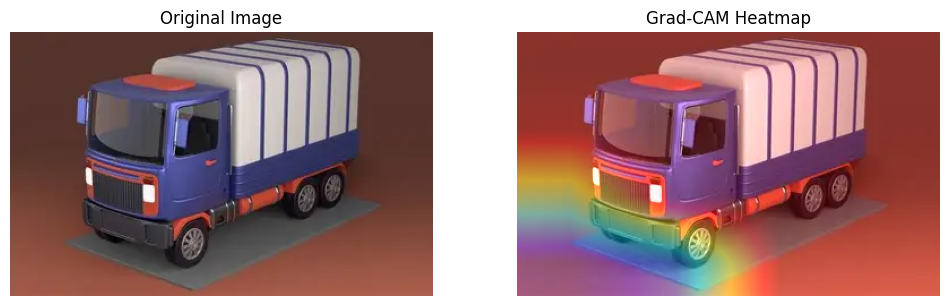

In [ ]:
# @title 8.1 NEW: Grad-CAM - Visualizing Where the Model Looks (Corrected for ResNet)

import torch.nn.functional as F
from PIL import Image
import cv2
import numpy as np

# This cell uses the image tensor from the upload cell (6.1).
# Make sure you have run that cell first.
try:
    _ = input_tensor
except NameError:
    print("Please run the 'Upload and Classify' cell (6.1) first to get an image tensor.")

# Hook to get the gradients and activations
gradients = None
activations = None
def backward_hook(module, grad_input, grad_output):
    global gradients; gradients = grad_output[0]
def forward_hook(module, input, output):
    global activations; activations = output

# --- THE FIX IS HERE ---
# Find the last convolutional layer in the ResNet model
target_layer = model.layer4[-1].conv2 # <--- UPDATED: This is the correct path for ResNet18
# -----------------------

h_forward = target_layer.register_forward_hook(forward_hook)
h_backward = target_layer.register_full_backward_hook(backward_hook)

# Get the prediction for the last uploaded image
output = model(input_tensor)
pred_class_idx = output.argmax(dim=1).item()

# Perform backward pass
model.zero_grad()
output[0][pred_class_idx].backward()

# Generate the heatmap
pooled_gradients = torch.mean(gradients, dim=[0, 2, 3])
for i in range(activations.shape[1]):
    activations[:, i, :, :] *= pooled_gradients[i]
heatmap = torch.mean(activations, dim=1).squeeze().detach().cpu()
heatmap = F.relu(heatmap)
heatmap /= torch.max(heatmap)
heatmap = heatmap.numpy()

# Remove hooks
h_forward.remove()
h_backward.remove()

# Superimpose heatmap on the original image
img = np.array(original_image)
heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
superimposed_img = np.clip(heatmap_colored * 0.4 + img, 0, 255).astype(np.uint8)

# Display the result
print(f"Prediction: {classes[pred_class_idx]}")
print("The heatmap shows the areas the model focused on to make this prediction.")
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(original_image); ax[0].set_title("Original Image"); ax[0].axis('off')
ax[1].imshow(superimposed_img); ax[1].set_title("Grad-CAM Heatmap"); ax[1].axis('off')
plt.show()